In [ ]:
from google.colab import files
uploaded = files.upload()

Saving model_table.csv to model_table.csv
Saving claim_lr_model.pkl to claim_lr_model.pkl
Saving claim_rf_model.pkl to claim_rf_model.pkl


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving risk_model.pkl to risk_model.pkl


=== Risk Model Classification Report ===
              precision    recall  f1-score   support

        High       0.16      0.01      0.01      1023
         Low       0.50      0.87      0.64      2480
      Medium       0.31      0.14      0.19      1497

    accuracy                           0.47      5000
   macro avg       0.32      0.34      0.28      5000
weighted avg       0.37      0.47      0.37      5000



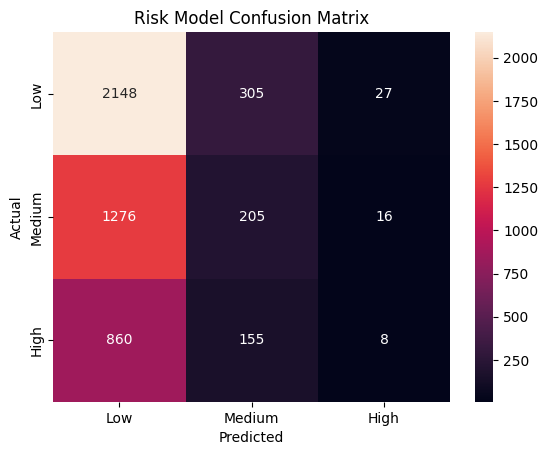

Recall for High Risk visits: 0.008

=== Claim Logistic Regression Classification Report ===
              precision    recall  f1-score   support

        Paid       0.95      0.95      0.95      2974
     Pending       0.88      0.89      0.88      1258
    Rejected       0.96      0.94      0.95       768

    accuracy                           0.93      5000
   macro avg       0.93      0.93      0.93      5000
weighted avg       0.93      0.93      0.93      5000



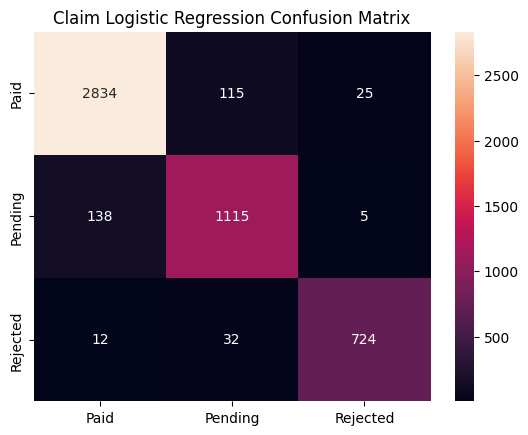


=== Claim Random Forest Classification Report ===
              precision    recall  f1-score   support

        Paid       0.86      0.98      0.92      2974
     Pending       0.92      0.64      0.76      1258
    Rejected       1.00      0.96      0.98       768

    accuracy                           0.89      5000
   macro avg       0.93      0.86      0.88      5000
weighted avg       0.90      0.89      0.89      5000



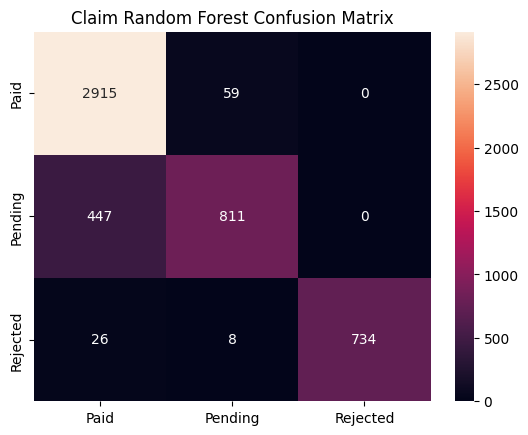

Recall for Rejected claims (RF): 0.956

Top 10 Risk Model Features:
                         feature  importance
1      num__length_of_stay_hours    0.141196
5   num__days_since_registration    0.130648
3        num__avg_length_of_stay    0.127361
0                       num__age    0.112516
6               num__visit_month    0.076157
2           num__visit_frequency    0.069790
7             num__visit_weekday    0.065856
4   num__provider_rejection_rate    0.046611
22            cat__visit_type_ER    0.016115
24           cat__visit_type_OPD    0.015838

Top 10 Claim Random Forest Features:
                         feature  importance
3           num__approved_amount    0.545711
2             num__billed_amount    0.108332
4              num__payment_days    0.064184
1      num__length_of_stay_hours    0.036927
8   num__days_since_registration    0.036087
6        num__avg_length_of_stay    0.035720
0                       num__age    0.032453
9               num__visit_month    0.0

In [ ]:
# ----------------------------
# Phase 4: Model Evaluation
# ----------------------------
import pandas as pd
import joblib
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
#  Load dataset
# ----------------------------
full_df = pd.read_csv("model_table.csv")

# Time-based test splits
risk_test_df = full_df.sort_values('visit_date').iloc[int(len(full_df)*0.8):]
claim_test_df = full_df.sort_values('billing_date').iloc[int(len(full_df)*0.8):]

# ----------------------------
#  Load trained models
# ----------------------------
risk_model = joblib.load('risk_model.pkl')
claim_lr_model = joblib.load('claim_lr_model.pkl')
claim_rf_model = joblib.load('claim_rf_model.pkl')

# ----------------------------
#  Define features and targets
# ----------------------------
risk_features = [
    'age','gender','chronic_flag','city','department','visit_type',
    'length_of_stay_hours','visit_frequency','avg_length_of_stay',
    'provider_rejection_rate','days_since_registration',
    'visit_month','visit_weekday'
]
X_risk_test = risk_test_df[risk_features]
y_risk_test = risk_test_df['risk_score']

claim_features = [
    'age','gender','chronic_flag','city','department','visit_type',
    'length_of_stay_hours','billed_amount','approved_amount','payment_days',
    'visit_frequency','avg_length_of_stay','provider_rejection_rate',
    'days_since_registration','visit_month','visit_weekday'
]
X_claim_test = claim_test_df[claim_features]
y_claim_test = claim_test_df['claim_status']

# Keep raw columns for subgroup/fairness analysis
X_risk_test_raw = risk_test_df[['gender', 'city']]
X_claim_test_raw = claim_test_df[['insurance_provider', 'city', 'gender']]

# ----------------------------
#  Evaluate Risk Model
# ----------------------------
y_risk_pred = risk_model.predict(X_risk_test)
print("=== Risk Model Classification Report ===")
print(classification_report(y_risk_test, y_risk_pred))

cm_risk = confusion_matrix(y_risk_test, y_risk_pred, labels=['Low','Medium','High'])
sns.heatmap(cm_risk, annot=True, fmt='d', xticklabels=['Low','Medium','High'], yticklabels=['Low','Medium','High'])
plt.title("Risk Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

high_risk_recall = cm_risk[2,2] / cm_risk[2].sum()
print(f"Recall for High Risk visits: {high_risk_recall:.3f}")

# ----------------------------
#  Evaluate Claim Models
# ----------------------------

# Logistic Regression
y_claim_pred_lr = claim_lr_model.predict(X_claim_test)
print("\n=== Claim Logistic Regression Classification Report ===")
print(classification_report(y_claim_test, y_claim_pred_lr))
cm_lr = confusion_matrix(y_claim_test, y_claim_pred_lr, labels=['Paid','Pending','Rejected'])
sns.heatmap(cm_lr, annot=True, fmt='d', xticklabels=['Paid','Pending','Rejected'], yticklabels=['Paid','Pending','Rejected'])
plt.title("Claim Logistic Regression Confusion Matrix")
plt.show()

# Random Forest
y_claim_pred_rf = claim_rf_model.predict(X_claim_test)
print("\n=== Claim Random Forest Classification Report ===")
print(classification_report(y_claim_test, y_claim_pred_rf))
cm_rf = confusion_matrix(y_claim_test, y_claim_pred_rf, labels=['Paid','Pending','Rejected'])
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=['Paid','Pending','Rejected'], yticklabels=['Paid','Pending','Rejected'])
plt.title("Claim Random Forest Confusion Matrix")
plt.show()

rejected_recall_rf = cm_rf[2,2] / cm_rf[2].sum()
print(f"Recall for Rejected claims (RF): {rejected_recall_rf:.3f}")

# ----------------------------
#  Feature Importance / Coefficients
# ----------------------------
# Risk model
risk_feature_names = risk_model.named_steps['preprocessor'].get_feature_names_out()
risk_importances = risk_model.named_steps['classifier'].feature_importances_
risk_fi_df = pd.DataFrame({'feature': risk_feature_names, 'importance': risk_importances}).sort_values('importance', ascending=False)
print("\nTop 10 Risk Model Features:")
print(risk_fi_df.head(10))

# Claim Random Forest
claim_rf_feature_names = claim_rf_model.named_steps['preprocessor'].get_feature_names_out()
claim_rf_importances = claim_rf_model.named_steps['classifier'].feature_importances_
claim_rf_fi_df = pd.DataFrame({'feature': claim_rf_feature_names, 'importance': claim_rf_importances}).sort_values('importance', ascending=False)
print("\nTop 10 Claim Random Forest Features:")
print(claim_rf_fi_df.head(10))

# Claim Logistic Regression
lr_coefs = claim_lr_model.named_steps['classifier'].coef_
lr_features = claim_lr_model.named_steps['preprocessor'].get_feature_names_out()
lr_coef_df = pd.DataFrame({'feature': lr_features, 'coefficient': lr_coefs[0]}).sort_values(by='coefficient', key=abs, ascending=False)
print("\nTop 10 Claim Logistic Regression Coefficients:")
print(lr_coef_df.head(10))

# ----------------------------
# Subgroup / Fairness Analysis
# ----------------------------
def subgroup_metrics(model, X_encoded, X_raw, y, group_col):
    print(f"\n--- Performance by {group_col} ---")
    for val, df_group in X_raw.groupby(group_col):
        y_true = y.loc[df_group.index]
        y_pred = model.predict(X_encoded.loc[df_group.index])
        print(f"\nGroup: {val}")
        print(classification_report(y_true, y_pred))

# Risk model by gender
subgroup_metrics(risk_model, X_risk_test, X_risk_test_raw, y_risk_test, 'gender')

# Claim RF by insurance provider
subgroup_metrics(claim_rf_model, X_claim_test, X_claim_test_raw, y_claim_test, 'insurance_provider')

# Claim RF by city
subgroup_metrics(claim_rf_model, X_claim_test, X_claim_test_raw, y_claim_test, 'city')

print("\nPhase 4 evaluation complete. Outputs ready for model card and explainability report.")